# Stage 1: Risky and risk-free assets

Portfolio theory starts by separating two kinds of asset:

- A **risky asset** has an uncertain return. We describe it by its expected return E(r) and its
  volatility σ.
- A **risk-free asset** has a known return over the holding period. Here that is the 91-day
  Treasury bill, whose nominal return is known at purchase.

This stage measures both, using **estimation months only** (February 2011 to October 2023). The
holdout is not touched. All means and volatilities are annualized and in INR.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from pmo import returns as ret
from pmo import stats
from pmo.config import load_config
from pmo.pipeline import load
from pmo.plotting import (DIVERGING, FIGURES, GRID, INK, MUTED, SERIES_1, SERIES_2, SERIES_3,
                          SURFACE, apply_style)

apply_style()
config = load_config()
data = load()
market = config.market_proxy
stocks = data.universe["symbol"].tolist()
sectors = data.universe.set_index("symbol")["sector"]

r = ret.select_period(data.returns, data.periods, "estimation")
rf = data.risk_free["rf"].loc[r.index]
equal_weight = r[stocks].mean(axis=1).rename("Equal weight")
print(f"{len(r)} months, {r.index.min().date()} to {r.index.max().date()}")

153 months, 2011-02-28 to 2023-10-31


## 1. The risk-free asset

The T-bill is free of default and price risk over its 91 days, with two limits:

- **The rate changes.** Rolling into a new bill each quarter carries reinvestment risk.
- **It is riskless only in nominal terms.** Inflation can still erode its real return.

Later stages need one number for the risk-free rate, so this cell measures the options.

In [2]:
rf_annual = rf * 12
rf_table = pd.Series({
    "Mean over estimation period": rf_annual.mean(),
    "Mean of last 12 estimation months": rf_annual.tail(12).mean(),
    "Lowest month": rf_annual.min(),
    "Highest month": rf_annual.max(),
    "Compound annual return": stats.geometric_return(rf),
    "Volatility of monthly returns": rf.std() * np.sqrt(12),
    "Market volatility, for scale": r[market].std() * np.sqrt(12),
}).to_frame("value")
rf_table.style.format("{:.2%}")

,value
Mean over estimation period,6.37%
Mean of last 12 estimation months,6.50%
Lowest month,2.82%
Highest month,10.51%
Compound annual return,6.56%
Volatility of monthly returns,0.50%
"Market volatility, for scale",16.42%


## 2. The risky assets

The summary below covers each stock, the market proxy and an equal-weight portfolio of all 25
stocks. `mean_se` is the standard error of the mean return, and `cvar_5` is the average monthly
return in the worst 5% of months.

In [3]:
summary = stats.asset_summary(pd.concat([r[stocks + [market]], equal_weight], axis=1), rf)
columns = ["mean", "cagr", "volatility", "mean_se", "sharpe", "sortino", "max_drawdown", "cvar_5"]
summary[columns].sort_values("sharpe", ascending=False).round(3)

,mean,cagr,volatility,mean_se,sharpe,sortino,max_drawdown,cvar_5
BAJFINANCE,0.471,0.474,0.392,0.110,1.041,1.897,-0.562,-0.195
Equal weight,0.190,0.192,0.158,0.044,0.794,1.330,-0.244,-0.079
HINDUNILVR,0.214,0.211,0.211,0.059,0.713,1.394,-0.243,-0.079
TITAN,0.284,0.260,0.319,0.089,0.689,1.112,-0.331,-0.179
HCLTECH,0.242,0.229,0.266,0.074,0.671,1.148,-0.267,-0.136
ASIANPAINT,0.233,0.222,0.254,0.071,0.667,1.244,-0.230,-0.112
NESTLEIND,0.187,0.182,0.193,0.054,0.638,1.066,-0.291,-0.094
KOTAKBANK,0.203,0.189,0.243,0.068,0.576,0.956,-0.276,-0.118
HDFCBANK,0.186,0.176,0.214,0.060,0.573,0.971,-0.324,-0.101
TCS,0.183,0.172,0.223,0.062,0.536,0.979,-0.196,-0.094


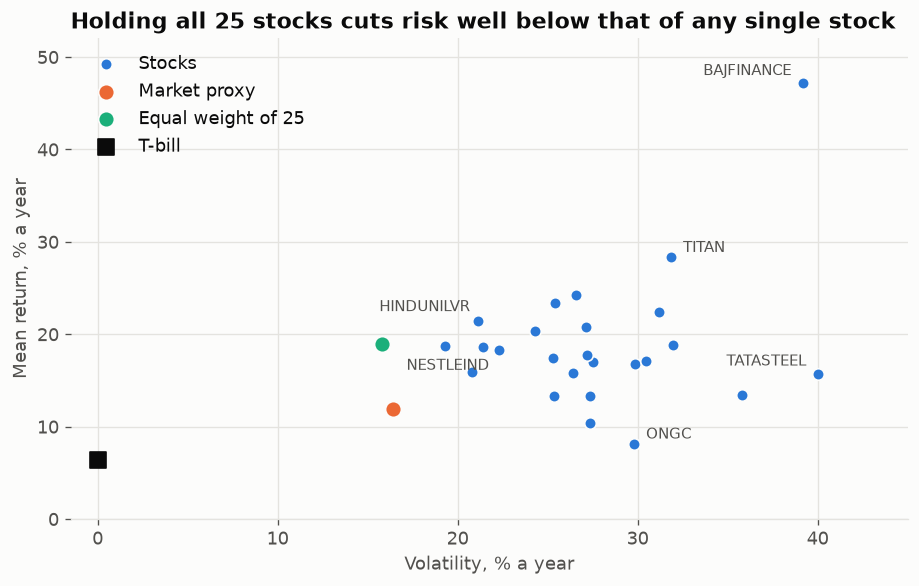

In [4]:
s = summary.loc[stocks]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.grid(axis="x")
ax.scatter(s["volatility"] * 100, s["mean"] * 100, s=48, color=SERIES_1, edgecolor=SURFACE,
           linewidth=1, label="Stocks", zorder=3)
points = [(market, "Market proxy", SERIES_2), ("Equal weight", "Equal weight of 25", SERIES_3)]
for name, label, color in points:
    row = summary.loc[name]
    ax.scatter(row["volatility"] * 100, row["mean"] * 100, s=90, color=color, edgecolor=SURFACE,
               linewidth=1, zorder=4, label=label)
ax.scatter(0, rf_annual.mean() * 100, s=90, marker="s", color=INK, zorder=4, label="T-bill")
labels = {"BAJFINANCE": (-7, 5, "right"), "HINDUNILVR": (-5, 6, "right"),
          "NESTLEIND": (2, -14, "center"), "ONGC": (7, 3, "left"), "TATASTEEL": (-7, 5, "right"),
          "TITAN": (7, 3, "left")}
for name, (dx, dy, align) in labels.items():
    ax.annotate(name, (s.loc[name, "volatility"] * 100, s.loc[name, "mean"] * 100),
                xytext=(dx, dy), textcoords="offset points", ha=align, fontsize=9, color=MUTED)
ax.set_xlim(-1.5, 45)
ax.set_ylim(0, 52)
ax.set_xlabel("Volatility, % a year")
ax.set_ylabel("Mean return, % a year")
ax.set_title("Holding all 25 stocks cuts risk well below that of any single stock")
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "01_risk_return.png")
plt.show()

Two cautions when reading this chart:

- **Higher risk did not reliably mean higher return.** Tata Steel and ONGC carried high volatility
  and earned little. Theory rewards only risk that cannot be diversified, which Stage 2 separates
  out and Stage 7 tests.
- **Survivorship flatters the stocks.** Nearly all of them beat the market proxy, which could not
  happen in a fair sample. They are today's winners, and the proxy is also missing some early
  dividends.

## 3. How much can we trust these numbers?

This matters more than any other result in this stage, because Markowitz optimization treats the
estimates as true. With 12.75 years of data, how precisely do we know each number?

- Standard error of a mean: σ / √years
- Standard error of a volatility: approximately σ / √(2 × months)

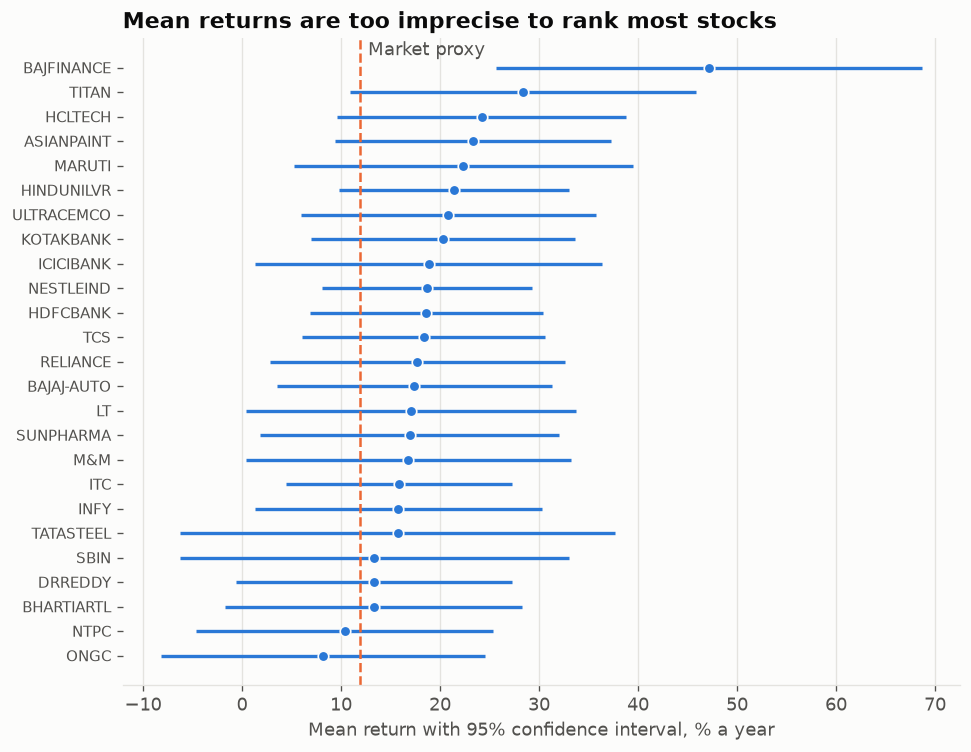

Significant at 5%: {'BAJFINANCE': 0.0001, 'TITAN': 0.0253}


,value
Median standard error of mean return (% a year),7.6
Median standard error of volatility (% a year),1.6
Median mean return (% a year),17.7
Median volatility (% a year),27.2
Stocks beating the market at the 5% level,2.0
"Same, corrected for testing 25 stocks",1.0


In [5]:
years = len(r) / 12
order = s.sort_values("mean").index
fig, ax = plt.subplots(figsize=(9, 7))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
positions = np.arange(len(order))
ax.hlines(positions, (s.loc[order, "mean"] - 1.96 * s.loc[order, "mean_se"]) * 100,
          (s.loc[order, "mean"] + 1.96 * s.loc[order, "mean_se"]) * 100, color=SERIES_1, linewidth=2)
ax.scatter(s.loc[order, "mean"] * 100, positions, s=40, color=SERIES_1, edgecolor=SURFACE, zorder=3)
ax.axvline(summary.loc[market, "mean"] * 100, color=SERIES_2, linewidth=1.5, linestyle="--")
ax.annotate("Market proxy", (summary.loc[market, "mean"] * 100, len(order) - 0.3), xytext=(5, 0),
            textcoords="offset points", color=MUTED, va="center")
ax.set_yticks(positions, order, fontsize=9)
ax.set_xlabel("Mean return with 95% confidence interval, % a year")
ax.set_title("Mean returns are too imprecise to rank most stocks")
fig.savefig(FIGURES / "01_mean_uncertainty.png")
plt.show()

difference = r[stocks].sub(r[market], axis=0)
pvalues = difference.apply(lambda col: sps.ttest_1samp(col, 0).pvalue)
vol_se_share = 1 / np.sqrt(2 * len(r))
precision = pd.Series({
    "Median standard error of mean return (% a year)": s["mean_se"].median() * 100,
    "Median standard error of volatility (% a year)": s["volatility"].median() * vol_se_share * 100,
    "Median mean return (% a year)": s["mean"].median() * 100,
    "Median volatility (% a year)": s["volatility"].median() * 100,
    "Stocks beating the market at the 5% level": (pvalues < 0.05).sum(),
    "Same, corrected for testing 25 stocks": (pvalues < 0.05 / len(stocks)).sum(),
}).round(1).to_frame("value")
print("Significant at 5%:", pvalues[pvalues < 0.05].round(4).to_dict())
precision

**Risk is measured far better than return.** This is the central practical problem of
portfolio optimization. An optimizer fed raw historical means will pile into whichever stocks got
lucky, so Stage 2 builds better return estimates and Stage 4 adds constraints.

## 4. Are returns normally distributed?

Mean-variance analysis uses only the mean and variance. That is complete only if returns are
normal or investors care only about those two numbers.

In [6]:
shape = summary.loc[stocks + [market], ["skew", "excess_kurtosis", "jarque_bera_p"]]
normality = pd.Series({
    "Assets rejecting normality at 5%": f"{(shape['jarque_bera_p'] < 0.05).sum()} of {len(shape)}",
    "Assets with negative skew": f"{(shape['skew'] < 0).sum()} of {len(shape)}",
    "Market skew": f"{shape.loc[market, 'skew']:.2f}",
    "Market excess kurtosis": f"{shape.loc[market, 'excess_kurtosis']:.2f}",
    "Worst market month": f"{r[market].min():.1%} ({r[market].idxmin():%b %Y})",
    "Normal model's chance of that month": f"{sps.norm.cdf(r[market].min(), r[market].mean(), r[market].std()):.1e}",
}).to_frame("value")
normality

,value
Assets rejecting normality at 5%,17 of 26
Assets with negative skew,7 of 26
Market skew,-0.60
Market excess kurtosis,3.48
Worst market month,-22.9% (Mar 2020)
Normal model's chance of that month,2.3e-07


Most series fail the normality test, and the market is the clearest case: large falls are
more common than a normal curve predicts. So volatility understates crash risk, and the final tool
should show drawdowns and stress results next to volatility.

## 5. Correlation

Diversification depends on correlations below 1. The matrix is ordered by sector, and the lines mark
sector boundaries.

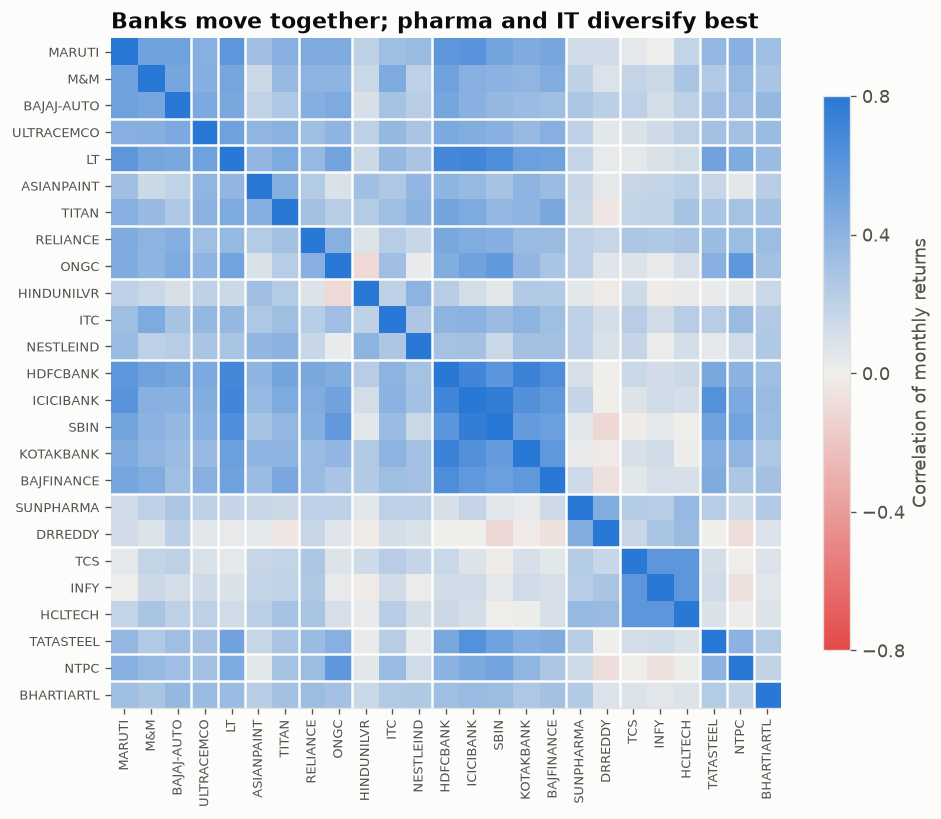

,correlation
Average pair,0.28
Same sector,0.54
Different sector,0.26
Lowest pair,-0.11
Highest pair,0.76


In [7]:
ordered = data.universe.sort_values("sector", kind="stable")["symbol"].tolist()
corr = r[ordered].corr()
fig, ax = plt.subplots(figsize=(9, 8))
ax.grid(False)
image = ax.imshow(corr, cmap=DIVERGING, vmin=-0.8, vmax=0.8)
ax.set_xticks(range(len(ordered)), ordered, rotation=90, fontsize=8)
ax.set_yticks(range(len(ordered)), ordered, fontsize=8)
boundaries = sectors[ordered].ne(sectors[ordered].shift()).to_numpy().nonzero()[0][1:] - 0.5
for edge in boundaries:
    ax.axhline(edge, color=SURFACE, linewidth=1.5)
    ax.axvline(edge, color=SURFACE, linewidth=1.5)
fig.colorbar(image, ax=ax, shrink=0.75, label="Correlation of monthly returns", ticks=[-0.8, -0.4, 0, 0.4, 0.8])
ax.set_title("Banks move together; pharma and IT diversify best")
fig.savefig(FIGURES / "01_correlation.png")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
same = pd.Series([sectors[a] == sectors[b] for a, b in pairs.index], index=pairs.index)
pd.Series({
    "Average pair": pairs.mean(),
    "Same sector": pairs[same].mean(),
    "Different sector": pairs[~same].mean(),
    "Lowest pair": pairs.min(),
    "Highest pair": pairs.max(),
}).round(2).to_frame("correlation")

## 6. Diversification

Portfolio variance depends on covariances as well as each stock's own risk. For an equal-weight
portfolio of n stocks:

σ²ₚ = (1/n) × average variance + (1 − 1/n) × average covariance

As n grows, the first term vanishes and the second remains. Stock-specific risk can be diversified
away, but market-wide risk cannot.

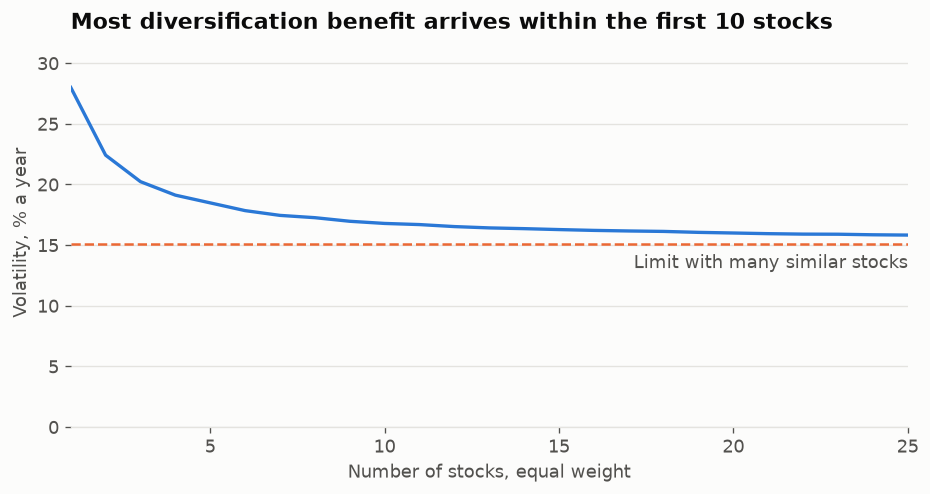

,mean_volatility,share_of_removable_risk_gone
size,,
1,0.280,0.000
2,0.224,0.433
5,0.185,0.737
10,0.168,0.868
15,0.163,0.908
25,0.158,0.943


In [8]:
curve = stats.diversification_curve(r[stocks], draws=2000)
floor = stats.diversification_floor(r[stocks])
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(curve.index, curve["mean_volatility"] * 100, color=SERIES_1)
ax.axhline(floor * 100, color=SERIES_2, linewidth=1.5, linestyle="--")
ax.annotate("Limit with many similar stocks", (25, floor * 100), xytext=(0, -6),
            textcoords="offset points", ha="right", va="top", color=MUTED)
ax.set_ylim(0, 32)
ax.set_xlim(1, 25)
ax.set_xlabel("Number of stocks, equal weight")
ax.set_ylabel("Volatility, % a year")
ax.set_title("Most diversification benefit arrives within the first 10 stocks")
fig.savefig(FIGURES / "01_diversification.png")
plt.show()

table = curve.loc[[1, 2, 5, 10, 15, 25]].copy()
removed = curve.iloc[0, 0] - floor
table["share_of_removable_risk_gone"] = (curve.iloc[0, 0] - table["mean_volatility"]) / removed
table.round(3)

## 7. Combining risky and risk-free assets

Mixing a risky asset with weight w and the T-bill with weight 1 − w gives:

- E(rₚ) = r_f + w × [E(r) − r_f]
- σₚ = w × σ

Because the T-bill has no volatility, **both are linear in w**. Every mix lies on a straight line
from the risk-free rate through the risky asset, called the capital allocation line. Its slope is
the Sharpe ratio. Stage 5 will look for the risky portfolio that gives the steepest possible line.

A weight above 1 means borrowing. Investors borrow above the T-bill rate, so the line bends
downward past w = 1. The 10% borrowing rate below is an illustrative assumption.

In [9]:
RISK_FREE = rf_annual.mean()
BORROW_RATE = 0.10
row = summary.loc[market]
allocation = stats.capital_allocation(row["mean"], row["volatility"], RISK_FREE,
                                      [0, 0.25, 0.5, 0.75, 1, 1.25, 1.5], borrow_rate=BORROW_RATE)
allocation["sharpe"] = (allocation["expected_return"] - RISK_FREE) / allocation["volatility"]
allocation.round(3)

,risky_weight,expected_return,volatility,sharpe
0,0.00,0.064,0.000,NaN
1,0.25,0.078,0.041,0.336
2,0.50,0.091,0.082,0.336
3,0.75,0.105,0.123,0.336
4,1.00,0.119,0.164,0.336
5,1.25,0.124,0.205,0.291
6,1.50,0.128,0.246,0.262


## Stage 1 conclusions

1. **Risk-free rate:** later stages use the estimation-period mean, about 6.4% a year, and test
   other values. Excess returns continue to use each month's actual rate.
2. **Return estimates are weak:** a typical stock's mean return has a standard error near 7.6
   percentage points, so raw historical means should not drive the optimizer.
3. **Risk estimates are strong:** the same stock's volatility has a standard error near 1.6 points.
4. **Diversification works, up to a limit:** average stock volatility of about 28% falls to about
   16% with 25 stocks, close to the 15% limit from shared market risk.
5. **Sectors matter:** correlations average about 0.54 within a sector and 0.26 across sectors, so
   sector caps will make sense in Stage 4.
6. **Volatility is not the whole story:** returns have fat tails, so drawdowns must be reported too.

These results use the estimation period only and describe the past, so they are not forecasts.